# Aspect-Based Sentiment Analysis of Product Reviews
### Traditional (TF-IDF) vs Transformer (BERT / RoBERTa) models on SemEval-2014 Laptops and MAMS

**Team:** Mrigank (230150018) · Varshit (230150023) · Jeshwanth (230150011)

This notebook reproduces every number and figure of the project and ends with a live demo.

| Section | Content |
|---|---|
| 0 | Setup and execution instructions |
| 1 | Data loading, preprocessing, BIO tagging |
| 2 | Exploratory data analysis |
| 3 | Training (v1 and v2 recipes) |
| 4 | Results: aspect sentiment classification (ASC) |
| 5 | Results: aspect term extraction (ATE) and end-to-end |
| 6 | Training curves |
| 7 | v1 → v2 improvements |
| 8 | Error analysis |
| 9 | Live demo |

## 0. Setup and execution instructions

**Requirements:** Python ≥ 3.10, an NVIDIA GPU with CUDA (tested on an RTX 4060 Laptop GPU, 8 GB).

```bash
pip install torch --index-url https://download.pytorch.org/whl/cu128   # CUDA build of PyTorch
pip install -r requirements.txt
```

**Data:** SemEval-2014 Task 4 Laptop XML files are in `data/`. MAMS (ATSA) is downloaded automatically
from the official repository (`siat-nlp/MAMS-for-ABSA`) into `data/MAMS/` on first run.

**Two ways to run**

1. Command line (recommended for full training):
   ```bash
   python run_all.py      # v1: EDA, baselines, BERT/RoBERTa-base for ATE + ASC   (~17 min on RTX 4060)
   python run_v2.py       # v2: improved recipe, RoBERTa-base and RoBERTa-large    (~75 min on RTX 4060)
   ```
   Both scripts are resumable (finished runs are skipped; `--fresh` retrains). `--quick` runs a 1-minute smoke test.
2. This notebook: set `RUN_TRAINING = True` below to launch the same scripts from here. With `False` the notebook
   reads the saved results in `results/` (v1) and `results_v2/` (v2) and only trains the small demo model in section 9.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

RUN_TRAINING = False   # True -> retrain everything (v1 + v2), ~1.5 h on an RTX 4060 laptop GPU

print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

V1, V2 = ROOT / "results", ROOT / "results_v2"
def show(path, width=None):
    display(Image(filename=str(path), width=width))

PyTorch 2.11.0+cu128 | CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Data loading and preprocessing

`absa/data.py` parses both corpora into one schema. XML files are parsed in parallel worker processes,
sentences are word-tokenised with character offsets, and aspect character spans are converted into BIO tags.
SemEval has no validation split, so 10% of its training *sentences* are held out (no sentence appears in two splits).
The rare SemEval `conflict` polarity is dropped for sentiment classification because MAMS has no such class.

In [2]:
from absa.data import load_datasets, describe
data = load_datasets()
describe(data)

[data] loading cached preprocessed data: datasets_c3705ac4bbc8.pkl


,dataset,split,sentences,sentences_with_aspects,aspect_terms(all),asc_instances,negative,neutral,positive
0,semeval,train,2741,1342,2133,2092,786,417,889
1,semeval,val,304,146,225,221,80,43,98
2,semeval,test,800,422,654,638,128,169,341
3,mams,train,4297,4297,11186,11186,2764,5042,3380
4,mams,val,500,500,1332,1332,325,604,403
5,mams,test,500,500,1336,1336,329,607,400


In [3]:
# one SemEval sentence with its BIO tags and gold aspects
s = next(x for x in data["semeval"]["train"]["sents"] if len(x["aspects"]) >= 2)
print(s["text"])
print(" ".join(f"{t}/{g}" for t, g in zip(s["tokens"], s["tags"])))
pd.DataFrame(s["aspects"])

Its good for playing my apps on Facebook or watching movies.
Its/O good/O for/O playing/B my/O apps/O on/O Facebook/O or/O watching/B movies/I ./O


,term,from,to,polarity
0,watching movies,44,59,positive
1,playing,13,20,positive


In [4]:
# the aspect-level view used for sentiment classification (one row per sentence-aspect pair)
data["mams"]["train"]["asc"][["text", "aspect", "polarity", "n_aspects", "n_polarities"]].head(6)

,text,aspect,polarity,n_aspects,n_polarities
0,The decor is not special at all but their food and amazing prices make up for it.,decor,negative,3,2
1,The decor is not special at all but their food and amazing prices make up for it.,food,positive,3,2
2,The decor is not special at all but their food and amazing prices make up for it.,prices,positive,3,2
3,"when tables opened up, the manager sat another party before us.",tables,neutral,2,2
4,"when tables opened up, the manager sat another party before us.",manager,negative,2,2
5,"Though the menu includes some unorthodox offerings (a peanut butter roll, for instance), the classics are pure and g...",menu,neutral,4,3


## 2. Exploratory data analysis

,dataset,mean_aspects_per_sentence(with>=1),share_sentences_multi_aspect,share_sentences_multi_polarity,mean_tokens,max_tokens,unique_aspect_terms
0,semeval,1.5770,0.1857,0.1084,16.7964,84,1181
1,mams,2.6154,1.0000,1.0000,26.8962,74,2877


unique aspect terms SemEval=879, MAMS=2410, shared=26 (Jaccard=0.008)



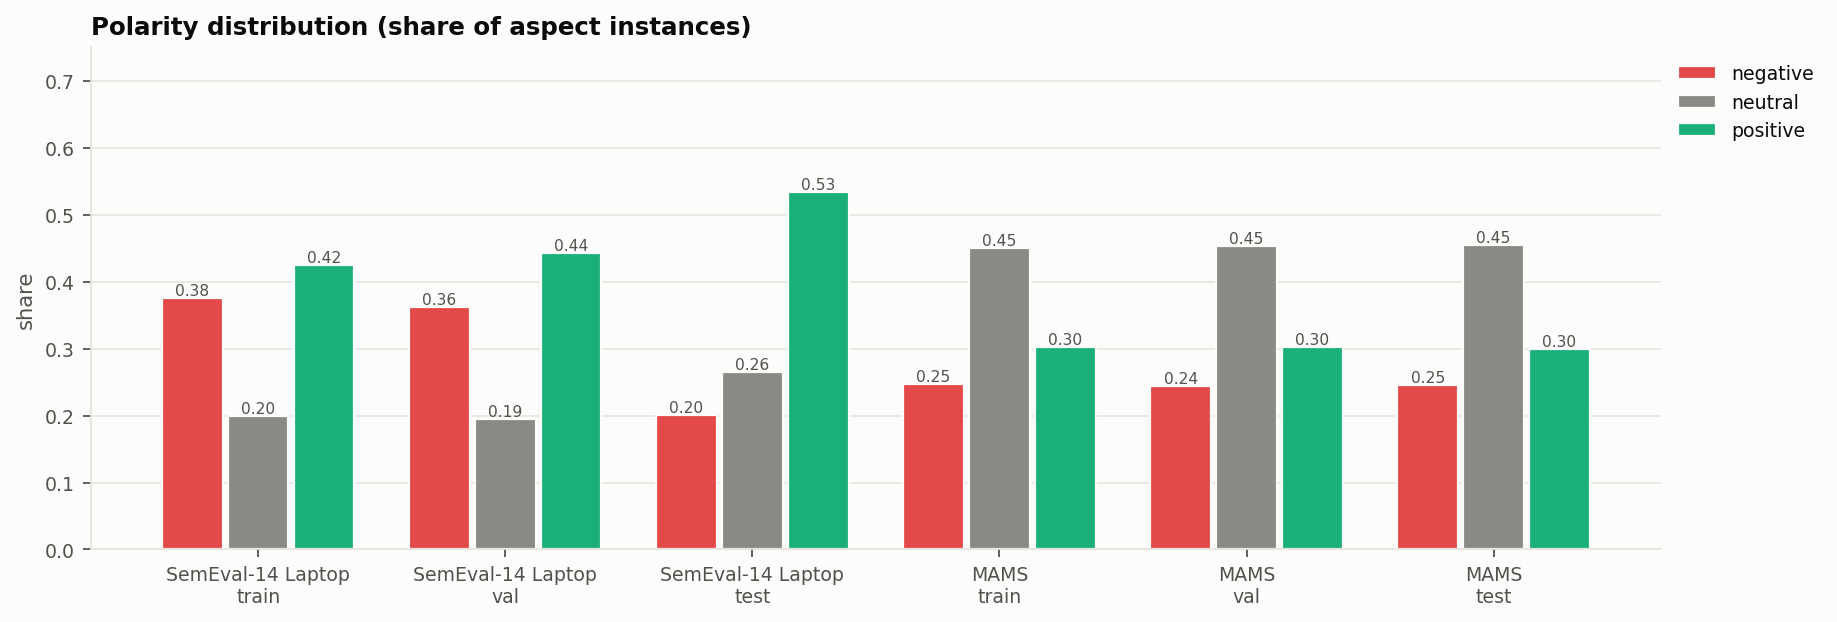

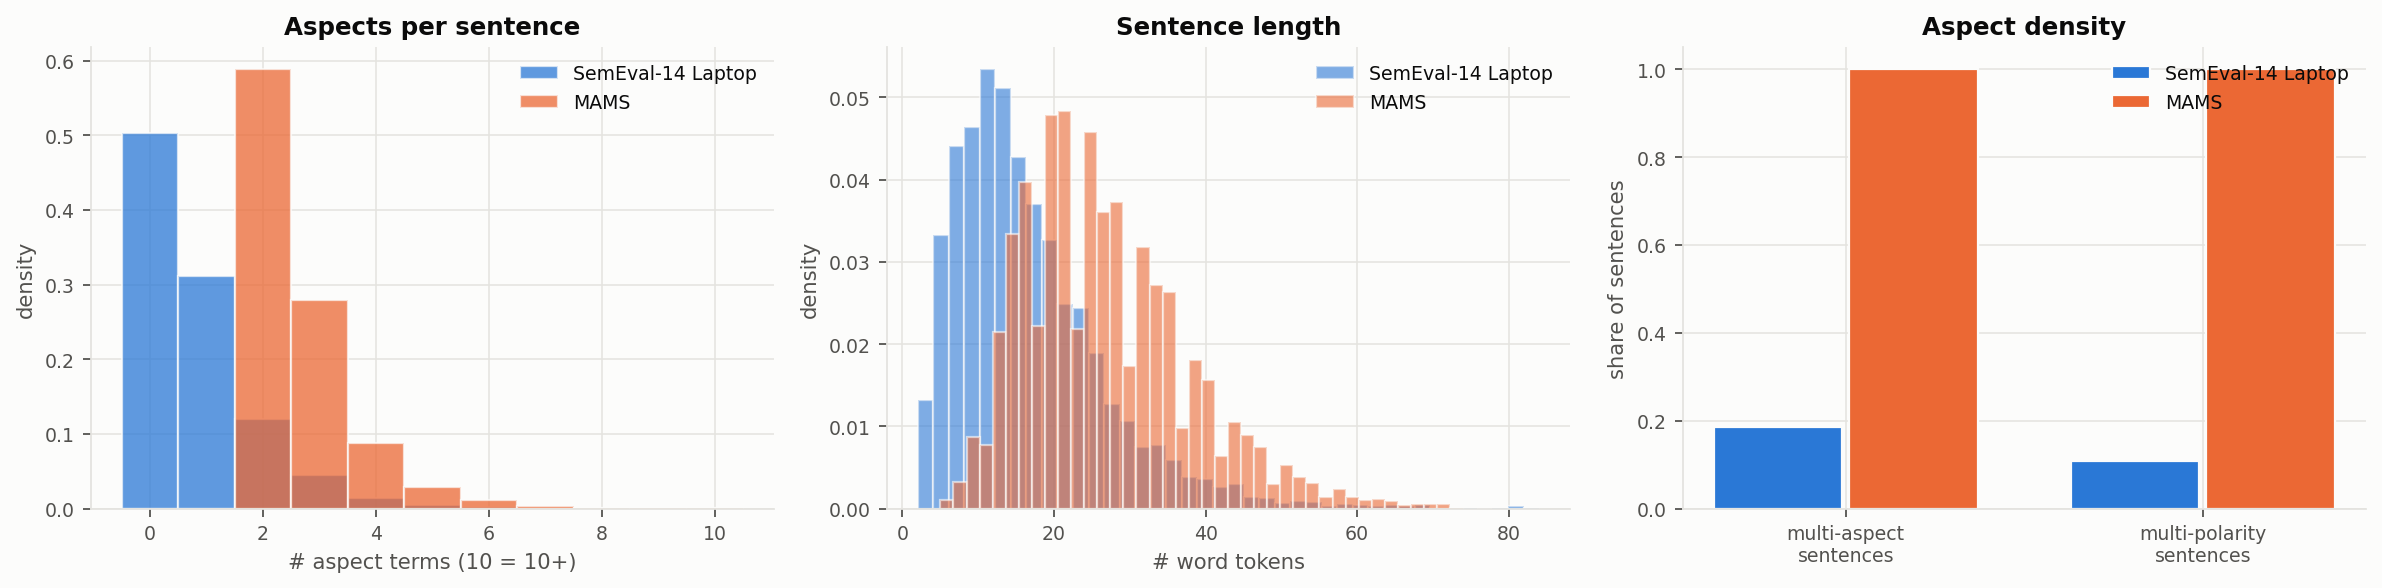

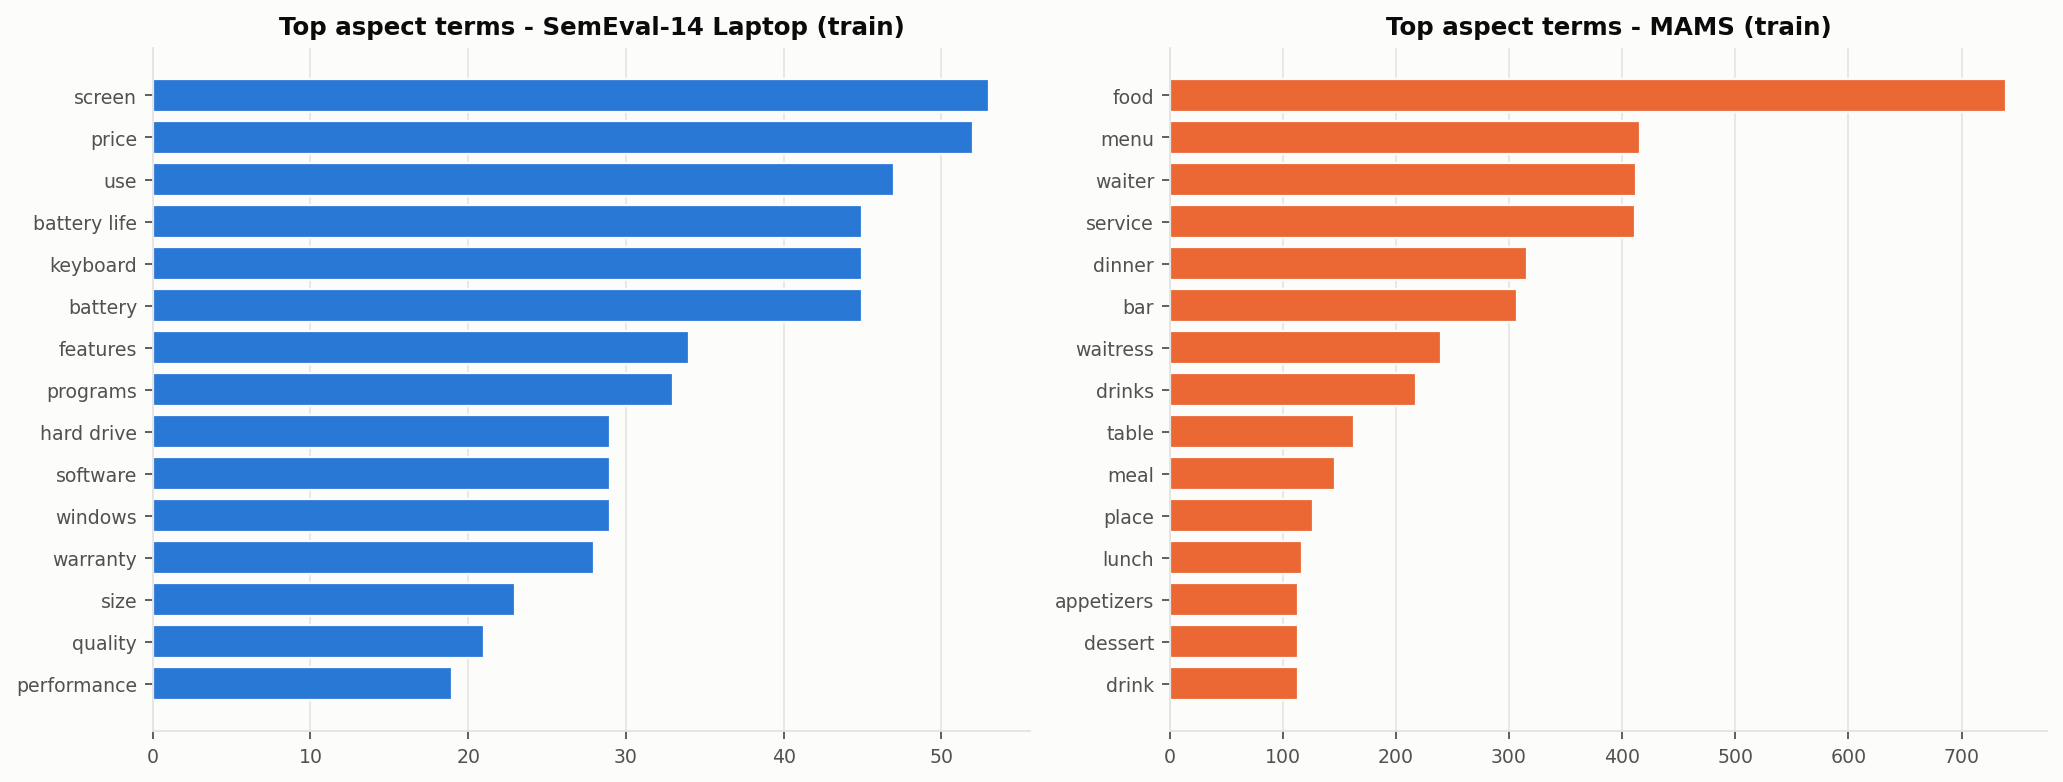

In [5]:
display(pd.read_csv(V1 / "eda" / "dataset_statistics.csv"))
print(open(V1 / "eda" / "vocab_overlap.txt").read())
show(V1 / "eda" / "polarity_distribution.png", 900)
show(V1 / "eda" / "aspects_and_lengths.png")
show(V1 / "eda" / "top_aspects.png")

## 3. Training

| | v1 recipe | v2 recipe |
|---|---|---|
| Models | BERT-base, RoBERTa-base | RoBERTa-base, RoBERTa-large |
| ASC input | (sentence, aspect) pair, [CLS] head | aspect marked in sentence with `#`, head on [CLS] ⊕ mean(aspect tokens) |
| Regularisation | weight decay | + label smoothing 0.1, FGM adversarial training, layer-wise LR decay |
| ATE decoding | per-token argmax | BIO-constrained Viterbi |
| Validation checks | 2 / epoch | 4 / epoch |

Shared settings: AdamW, linear warm-up/decay, bf16 mixed precision on the GPU, early stopping on validation
macro-F1 (ASC) or span F1 (ATE), best checkpoint restored before testing. Every model is trained on one corpus and
tested on both test sets (two in-domain and two cross-dataset configurations).

In [6]:
if RUN_TRAINING:
    for script in ["run_all.py", "run_v2.py"]:
        subprocess.run([sys.executable, script], check=True)
else:
    print("RUN_TRAINING = False -> using saved results")
    print(open(V2 / "run_log.txt", encoding="utf-8").read()[-1500:])

RUN_TRAINING = False -> using saved results
al main metric)

| model | task | train | best_epoch | train_metric | val_metric | gap |
|---|---|---|---|---|---|---|
| BERT-base v1 | asc | mams | 5.5000 | 0.9876 | 0.8243 | 0.1634 |
| RoBERTa-base v1 | asc | mams | 5.0000 | 0.9822 | 0.8306 | 0.1516 |
| RoBERTa-base v2 | asc | mams | 1.5000 | 0.9104 | 0.8322 | 0.0782 |
| RoBERTa-large v2 | asc | mams | 2.7500 | 0.9602 | 0.8315 | 0.1287 |
| BERT-base v1 | asc | semeval | 3.5000 | 0.8926 | 0.7095 | 0.1830 |
| RoBERTa-base v1 | asc | semeval | 2.5000 | 0.8374 | 0.7877 | 0.0497 |
| RoBERTa-base v2 | asc | semeval | 4.5040 | 0.9944 | 0.7758 | 0.2186 |
| RoBERTa-large v2 | asc | semeval | 1.7480 | 0.9186 | 0.7910 | 0.1275 |
| BERT-base v1 | ate | mams | 5.0000 | 0.9728 | 0.7761 | 0.1967 |
| RoBERTa-base v1 | ate | mams | 6.5040 | 0.9591 | 0.7840 | 0.1751 |
| RoBERTa-base v2 | ate | mams | 3.0000 | 0.8742 | 0.7893 | 0.0849 |
| RoBERTa-large v2 | ate | mams | 5.0000 | 0.9296 | 0.7802 | 0.1494 |
| B

## 4. Results: aspect-level sentiment classification (test sets)

In [7]:
asc = pd.read_csv(V2 / "tables" / "asc_results.csv")
asc["config"] = asc.train + " → " + asc.test
order = ["semeval → semeval", "mams → mams", "semeval → mams", "mams → semeval"]
models = list(dict.fromkeys(asc.model))
for metric in ["macro_f1", "accuracy"]:
    display(Markdown(f"**{metric}**"))
    display(asc.pivot(index="model", columns="config", values=metric).loc[models, order])

**macro_f1**

config,semeval → semeval,mams → mams,semeval → mams,mams → semeval
model,,,,
TF-IDF+LR,0.6067,0.7030,0.4465,0.5234
TF-IDF+SVM,0.5918,0.7127,0.4189,0.5112
BERT-base v1,0.7321,0.8326,0.5180,0.6769
RoBERTa-base v1,0.7748,0.8403,0.4824,0.7208
RoBERTa-base v2,0.7790,0.8449,0.5739,0.6911
RoBERTa-large v2,0.7988,0.8506,0.5416,0.7321


**accuracy**

config,semeval → semeval,mams → mams,semeval → mams,mams → semeval
model,,,,
TF-IDF+LR,0.6708,0.7148,0.4476,0.5925
TF-IDF+SVM,0.6646,0.7253,0.4274,0.5784
BERT-base v1,0.7759,0.8368,0.5165,0.6991
RoBERTa-base v1,0.8041,0.8451,0.4873,0.7539
RoBERTa-base v2,0.8197,0.8503,0.5831,0.7273
RoBERTa-large v2,0.8323,0.8563,0.5561,0.7618


In [8]:
display(Markdown("**Per-class F1 (in-domain)**"))
asc[asc.train == asc.test].pivot_table(index="model", columns="test", values=["negative_f1", "neutral_f1", "positive_f1"]).loc[models]

**Per-class F1 (in-domain)**

negative_f1         neutral_f1         positive_f1        
test                    mams semeval       mams semeval        mams semeval
model                                                                      
TF-IDF+LR             0.6910  0.5329     0.7731  0.4825      0.6448  0.8046
TF-IDF+SVM            0.6935  0.5490     0.7804  0.4247      0.6641  0.8017
BERT-base v1          0.8131  0.7152     0.8550  0.6034      0.8298  0.8778
RoBERTa-base v1       0.8192  0.7542     0.8645  0.6809      0.8372  0.8892
RoBERTa-base v2       0.8235  0.8027     0.8724  0.6272      0.8388  0.9072
RoBERTa-large v2      0.8207  0.7893     0.8765  0.6906      0.8546  0.9164

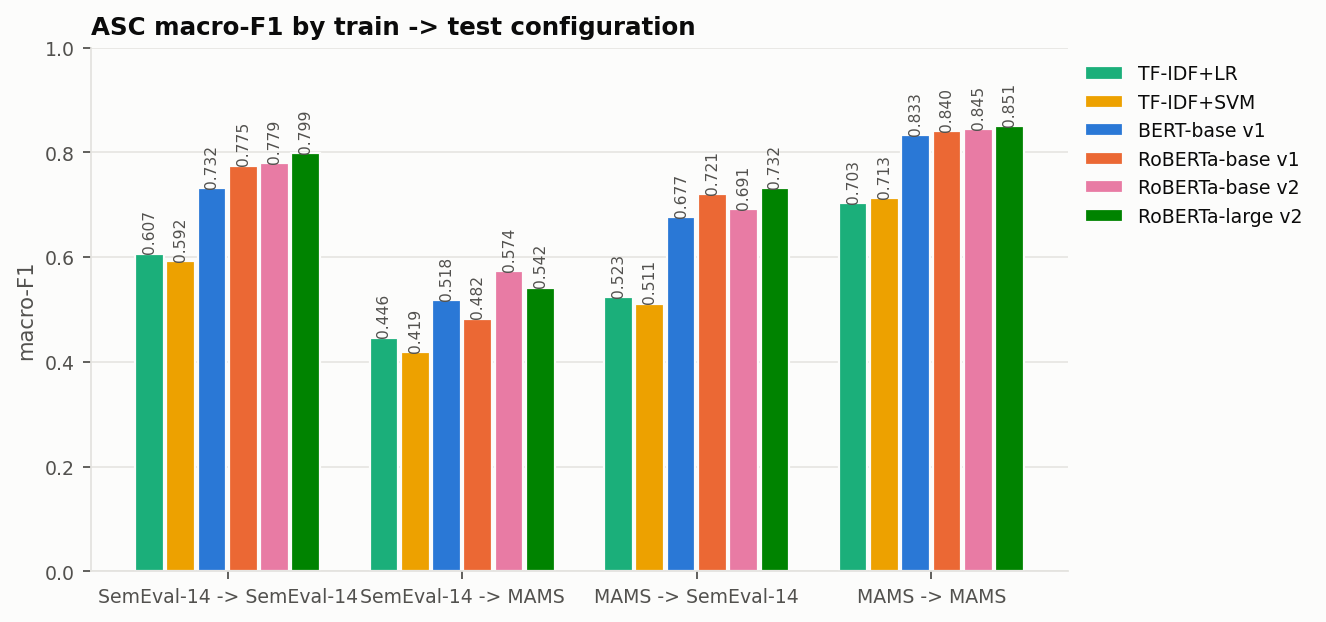

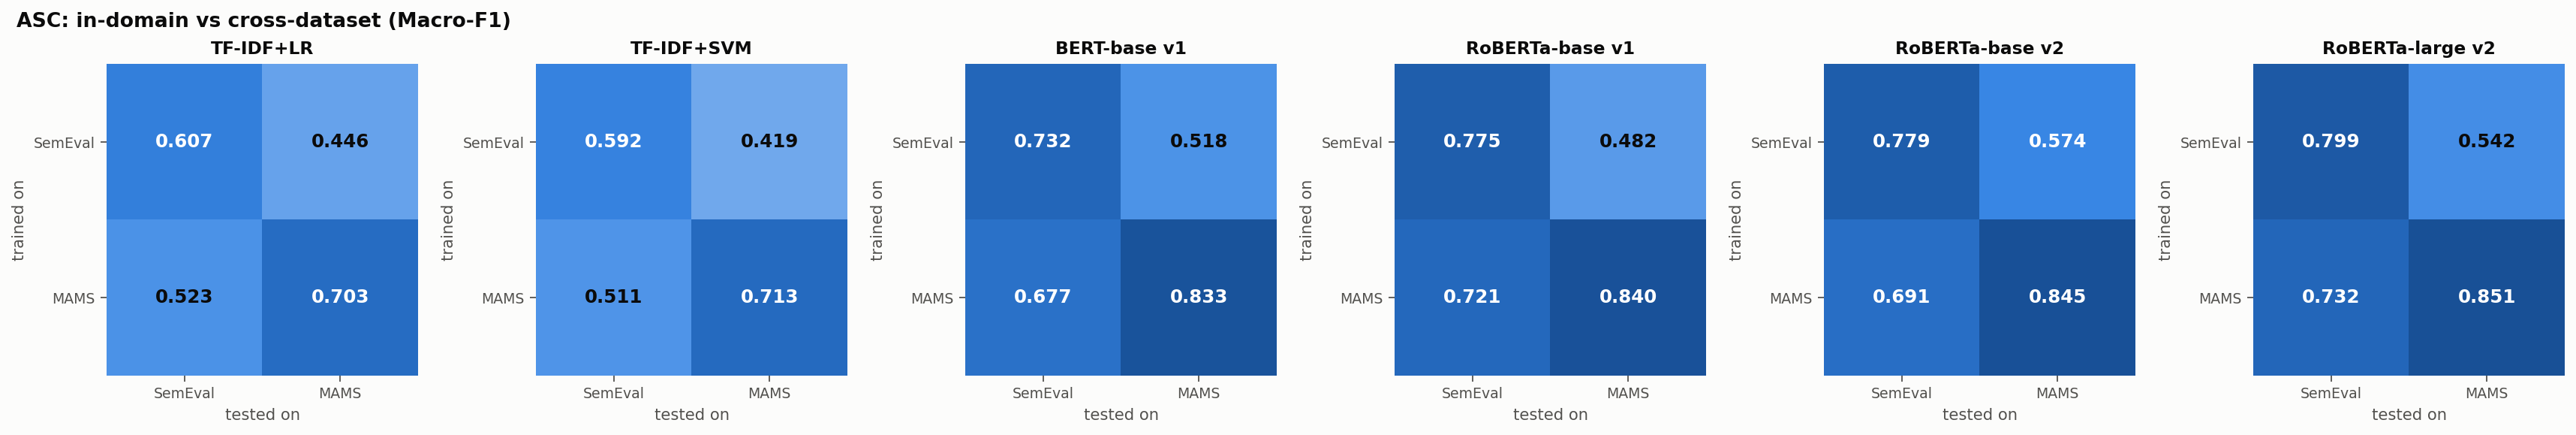

In [9]:
show(V2 / "figures" / "asc_model_comparison_macro_f1.png")
show(V2 / "figures" / "asc_cross_dataset_macro_f1.png")

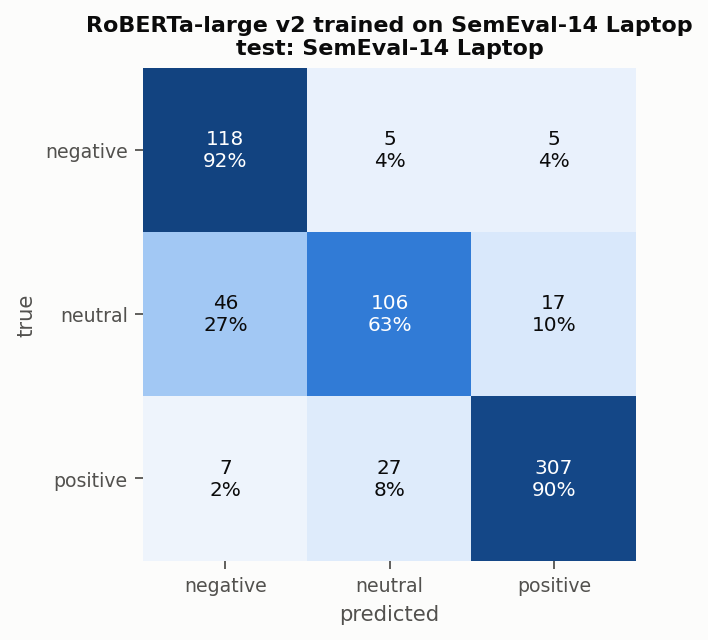

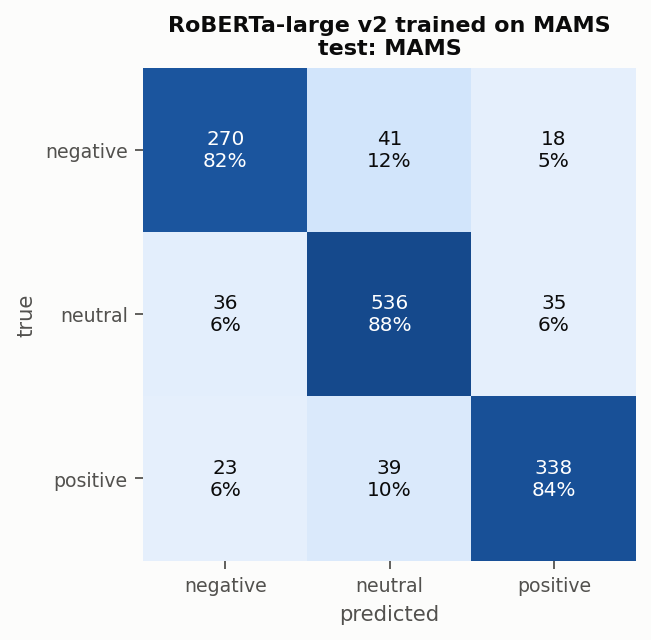

In [10]:
# confusion matrices of the best model, in-domain
for d in ["semeval", "mams"]:
    show(V2 / "transformers" / "asc" / f"roberta-large-v2_train-{d}" / f"confusion_test_{d}.png", 380)

## 5. Results: aspect term extraction and end-to-end pipeline

**ATE exact-match span F1**

config,semeval → semeval,mams → mams,semeval → mams,mams → semeval
model,,,,
TF-IDF+LR,0.5785,0.6863,0.1956,0.1106
BERT-base v1,0.8139,0.7503,0.2419,0.3161
RoBERTa-base v1,0.8591,0.7620,0.4396,0.3948
RoBERTa-base v2,0.8456,0.7801,0.3825,0.4149
RoBERTa-large v2,0.8607,0.7683,0.3808,0.4032


**End-to-end ATE → ASC (aspect span and polarity both correct), pair F1**

config,semeval → semeval,mams → mams,semeval → mams,mams → semeval
model,,,,
TF-IDF+LR,0.4138,0.5211,0.1082,0.0651
TF-IDF+SVM,0.4054,0.5291,0.1009,0.0651
BERT-base v1,0.6352,0.6424,0.1421,0.2458
RoBERTa-base v1,0.6914,0.6550,0.2757,0.2986
RoBERTa-base v2,0.7017,0.6713,0.2883,0.3079
RoBERTa-large v2,0.7095,0.6619,0.2950,0.3257


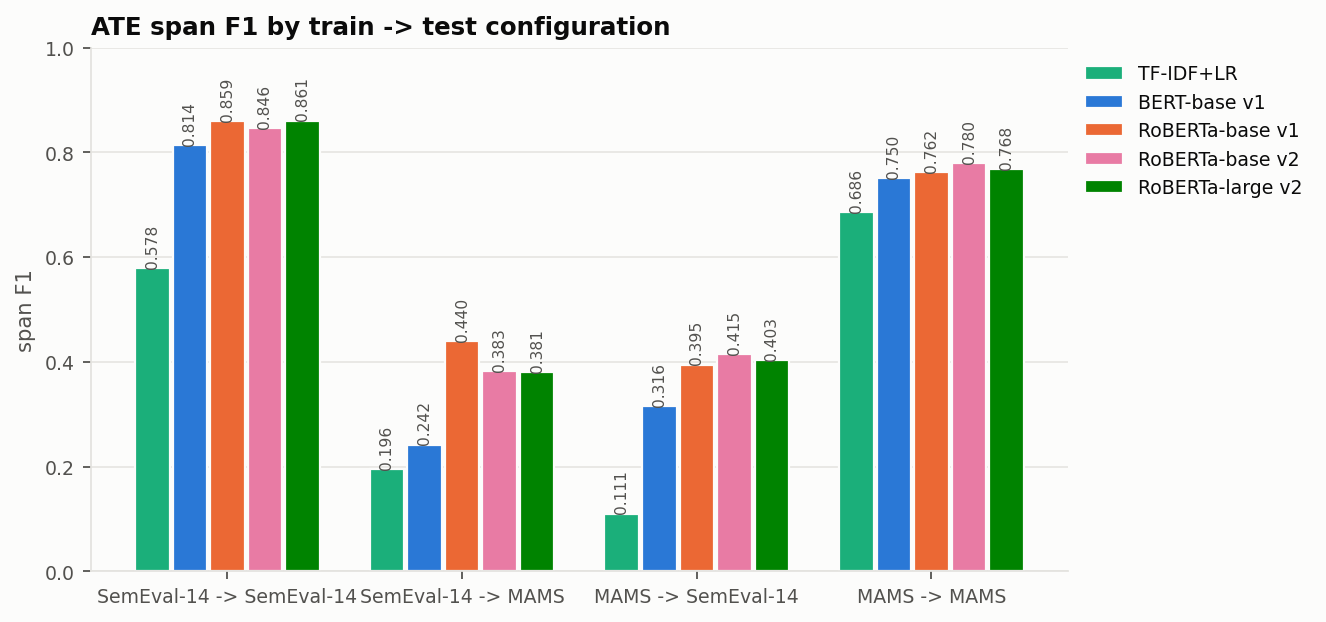

In [11]:
ate = pd.read_csv(V2 / "tables" / "ate_results.csv")
ate["config"] = ate.train + " → " + ate.test
display(Markdown("**ATE exact-match span F1**"))
display(ate.pivot(index="model", columns="config", values="f1").loc[list(dict.fromkeys(ate.model)), order])
e2e = pd.read_csv(V2 / "tables" / "end2end_results.csv")
e2e["config"] = e2e.train + " → " + e2e.test
display(Markdown("**End-to-end ATE → ASC (aspect span and polarity both correct), pair F1**"))
display(e2e.pivot(index="model", columns="config", values="f1").loc[list(dict.fromkeys(e2e.model)), order])
show(V2 / "figures" / "ate_model_comparison_f1.png")

## 6. Training curves

Each figure shows (left) training loss per step and per evaluation pass together with validation loss,
(middle and right) the main metrics on the training and validation sets. The dotted line marks the restored checkpoint.

**v1 · ASC · roberta_train-semeval**

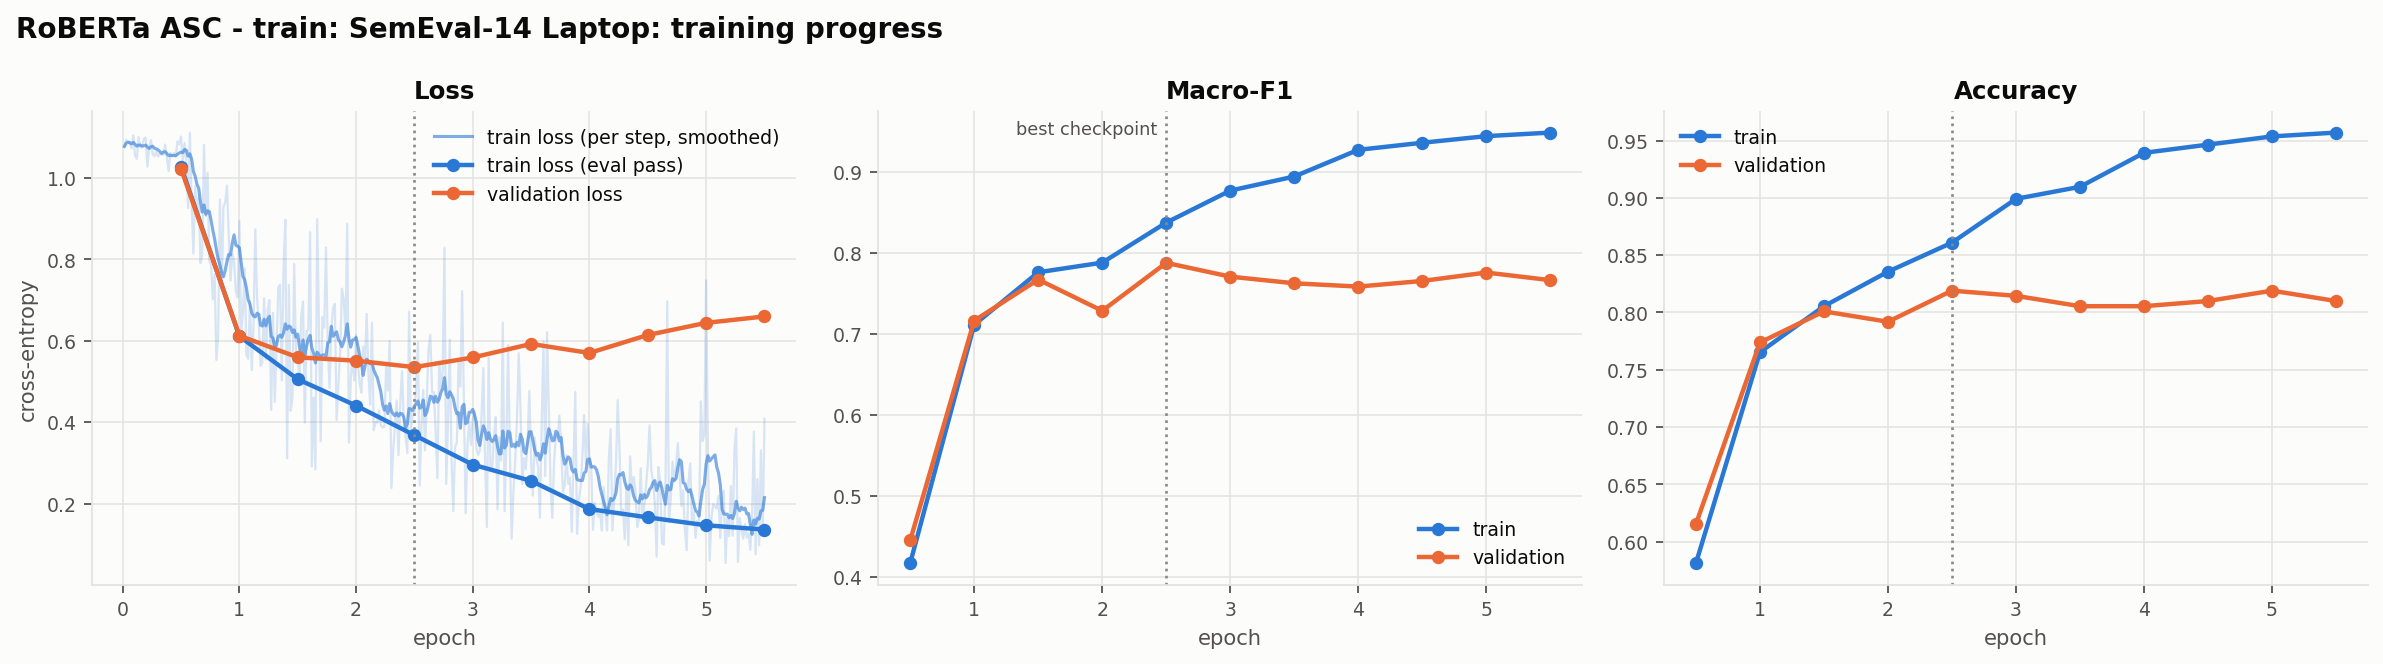

**v1 · ASC · roberta_train-mams**

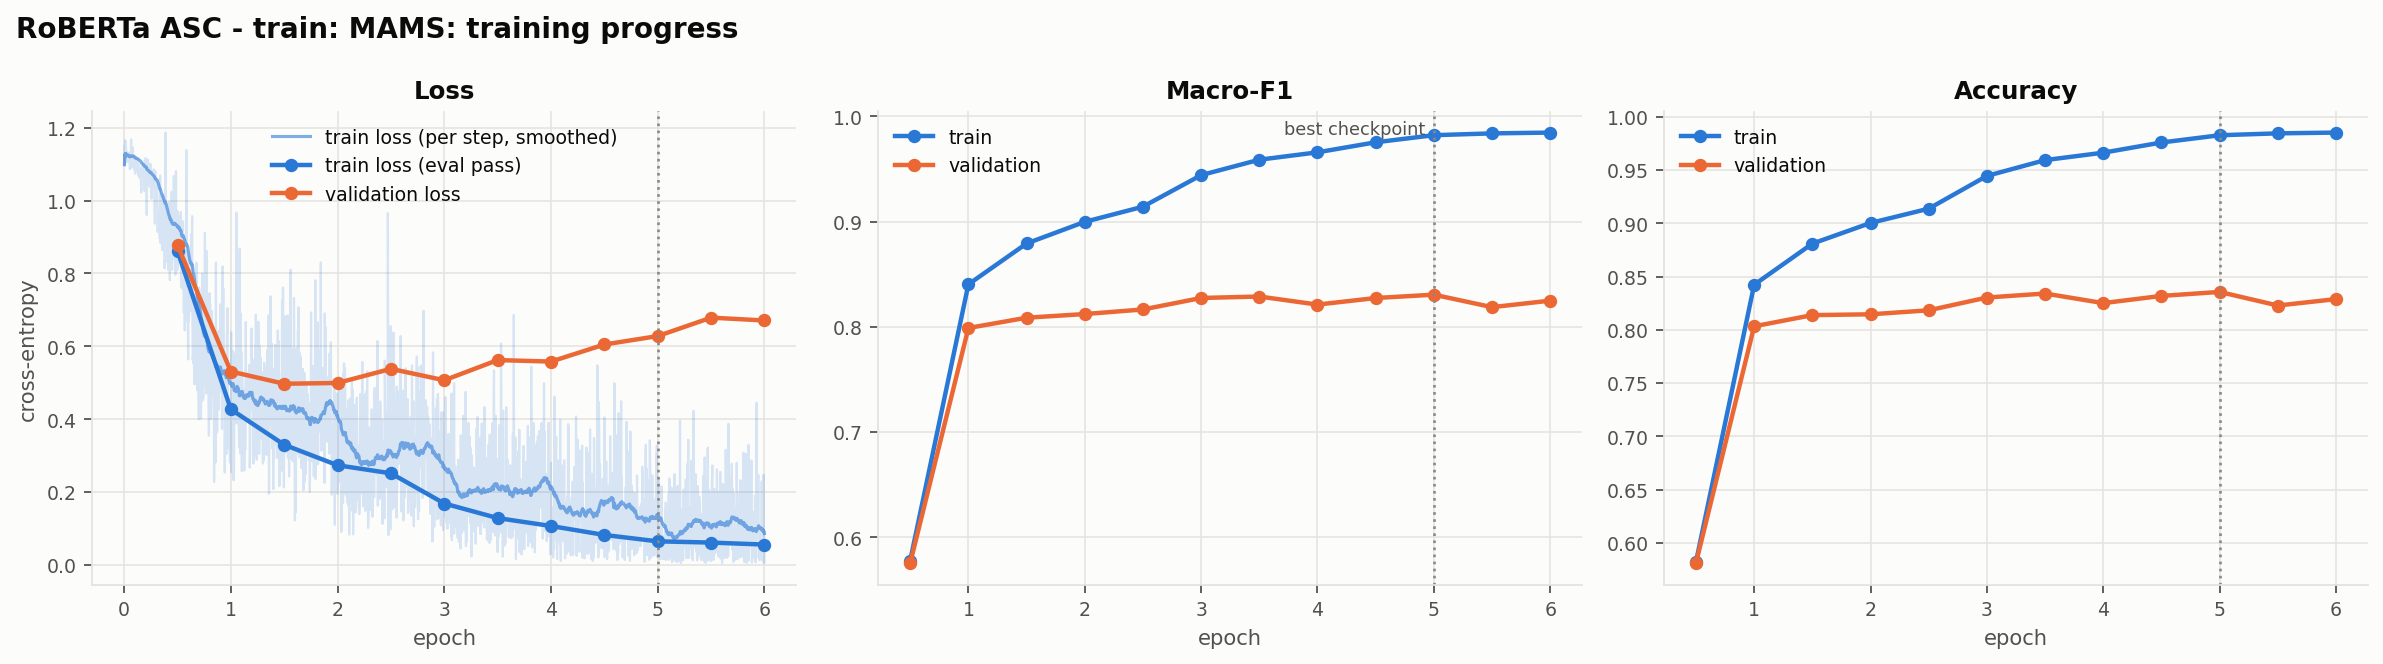

**v1 · ATE · roberta_train-semeval**

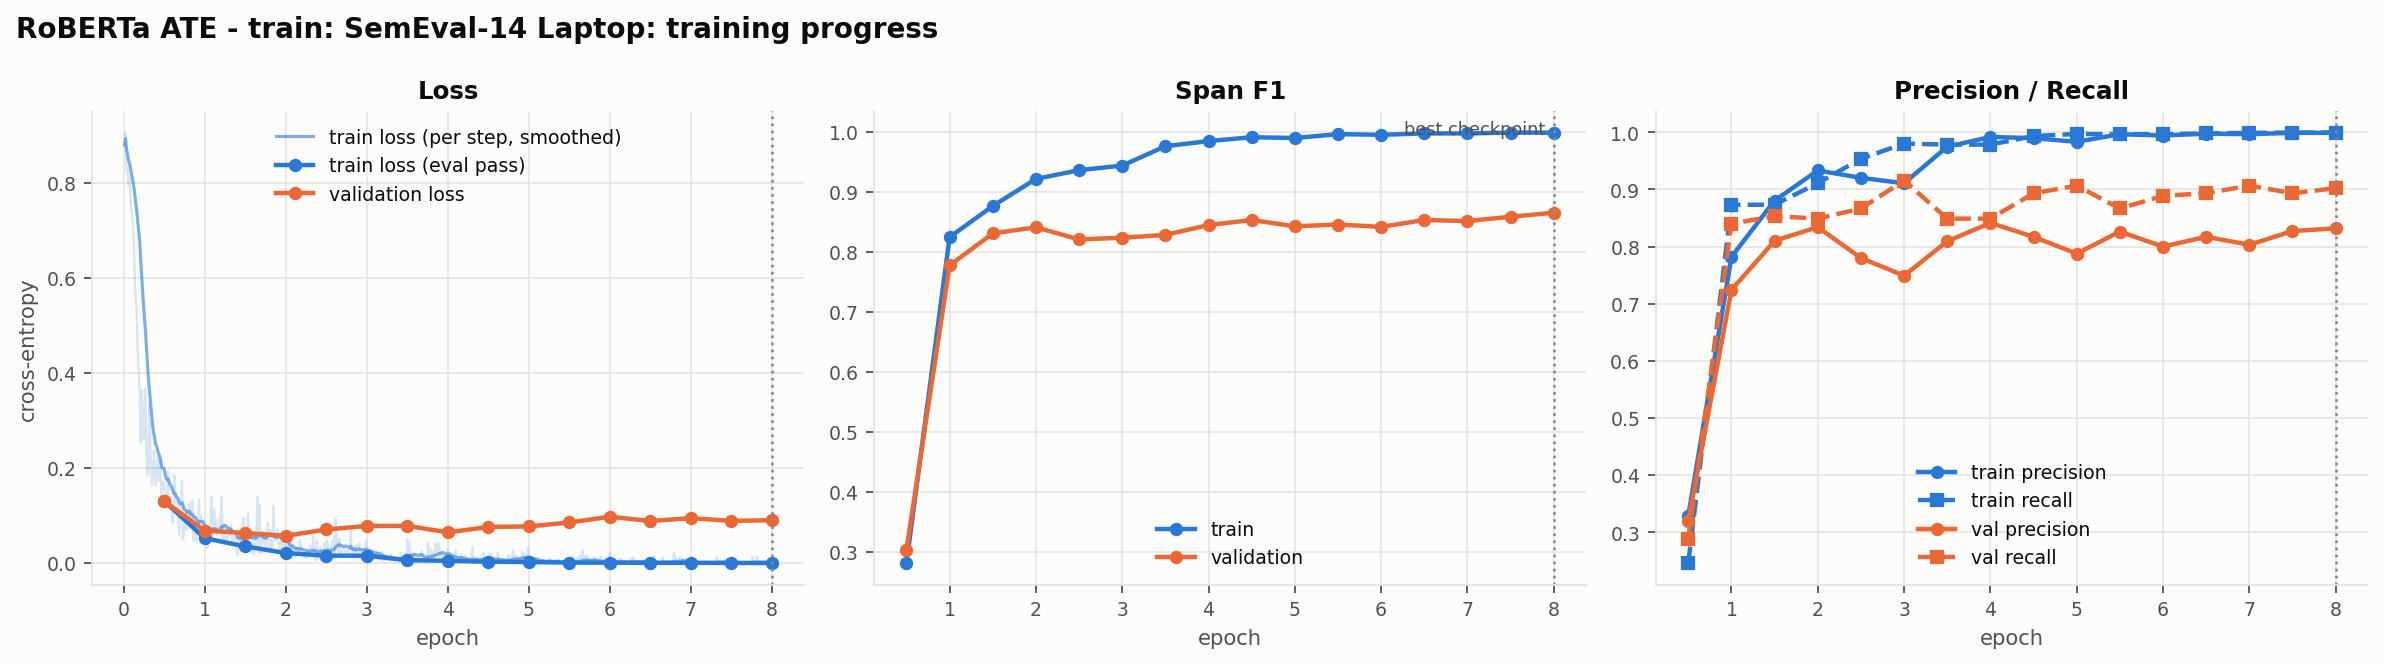

In [12]:
for task, run in [("asc", "roberta_train-semeval"), ("asc", "roberta_train-mams"), ("ate", "roberta_train-semeval")]:
    display(Markdown(f"**v1 · {task.upper()} · {run}**"))
    show(V1 / "transformers" / task / run / "training_curves.png")

**v2 · ASC · roberta-large-v2_train-semeval**

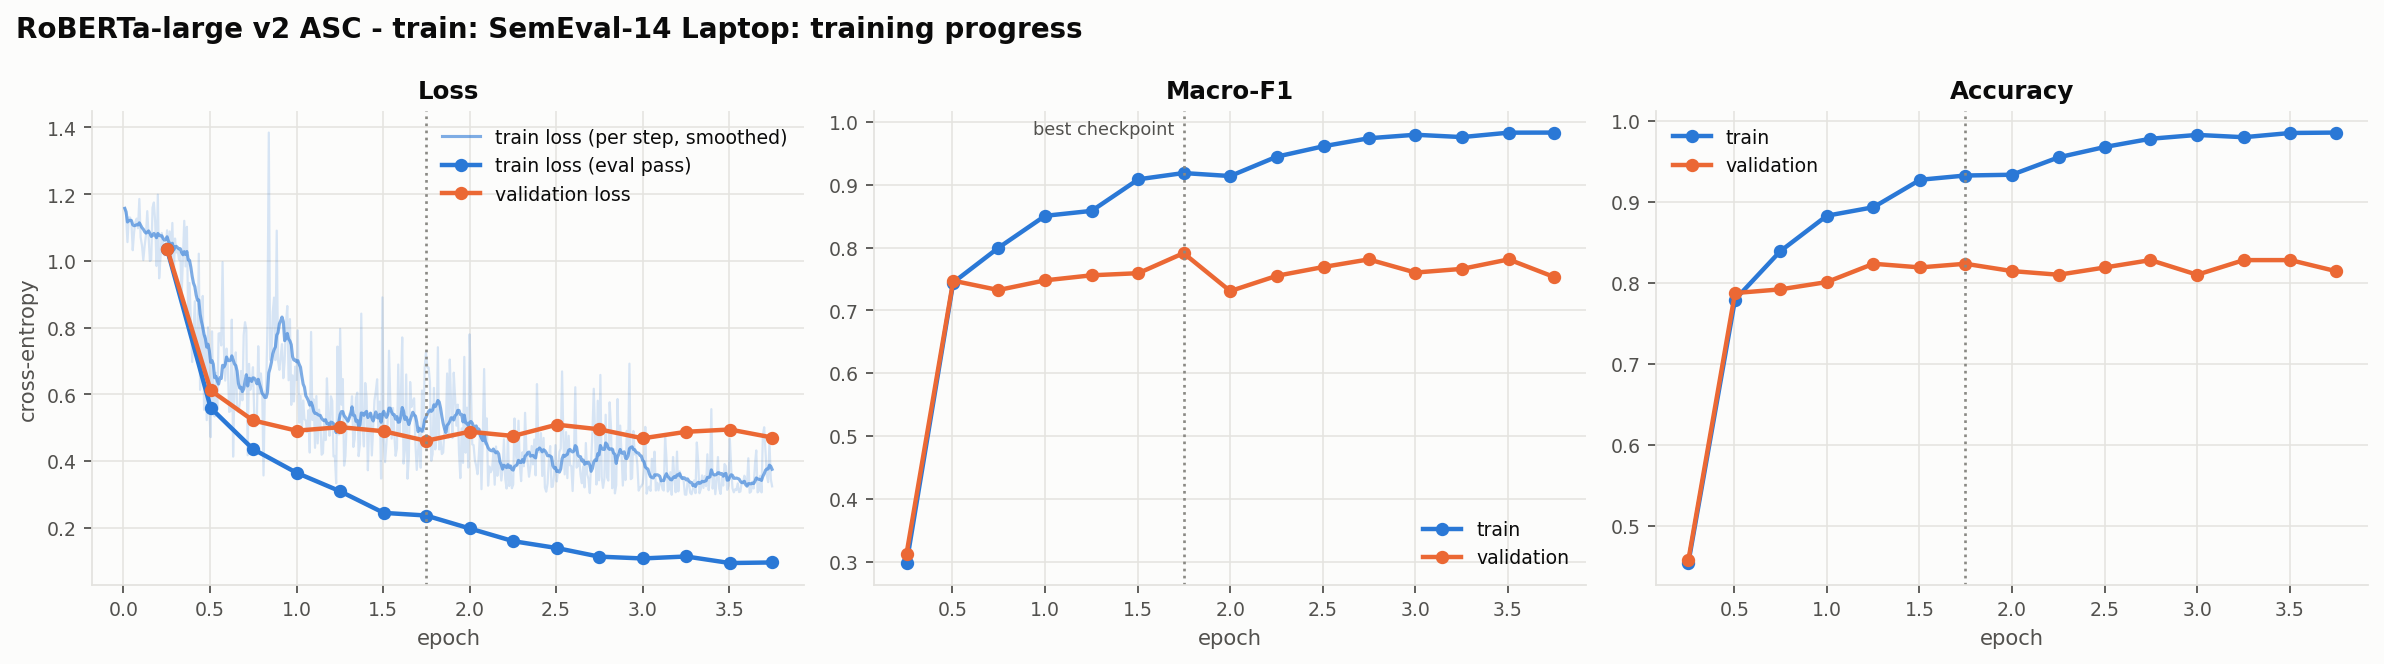

**v2 · ASC · roberta-large-v2_train-mams**

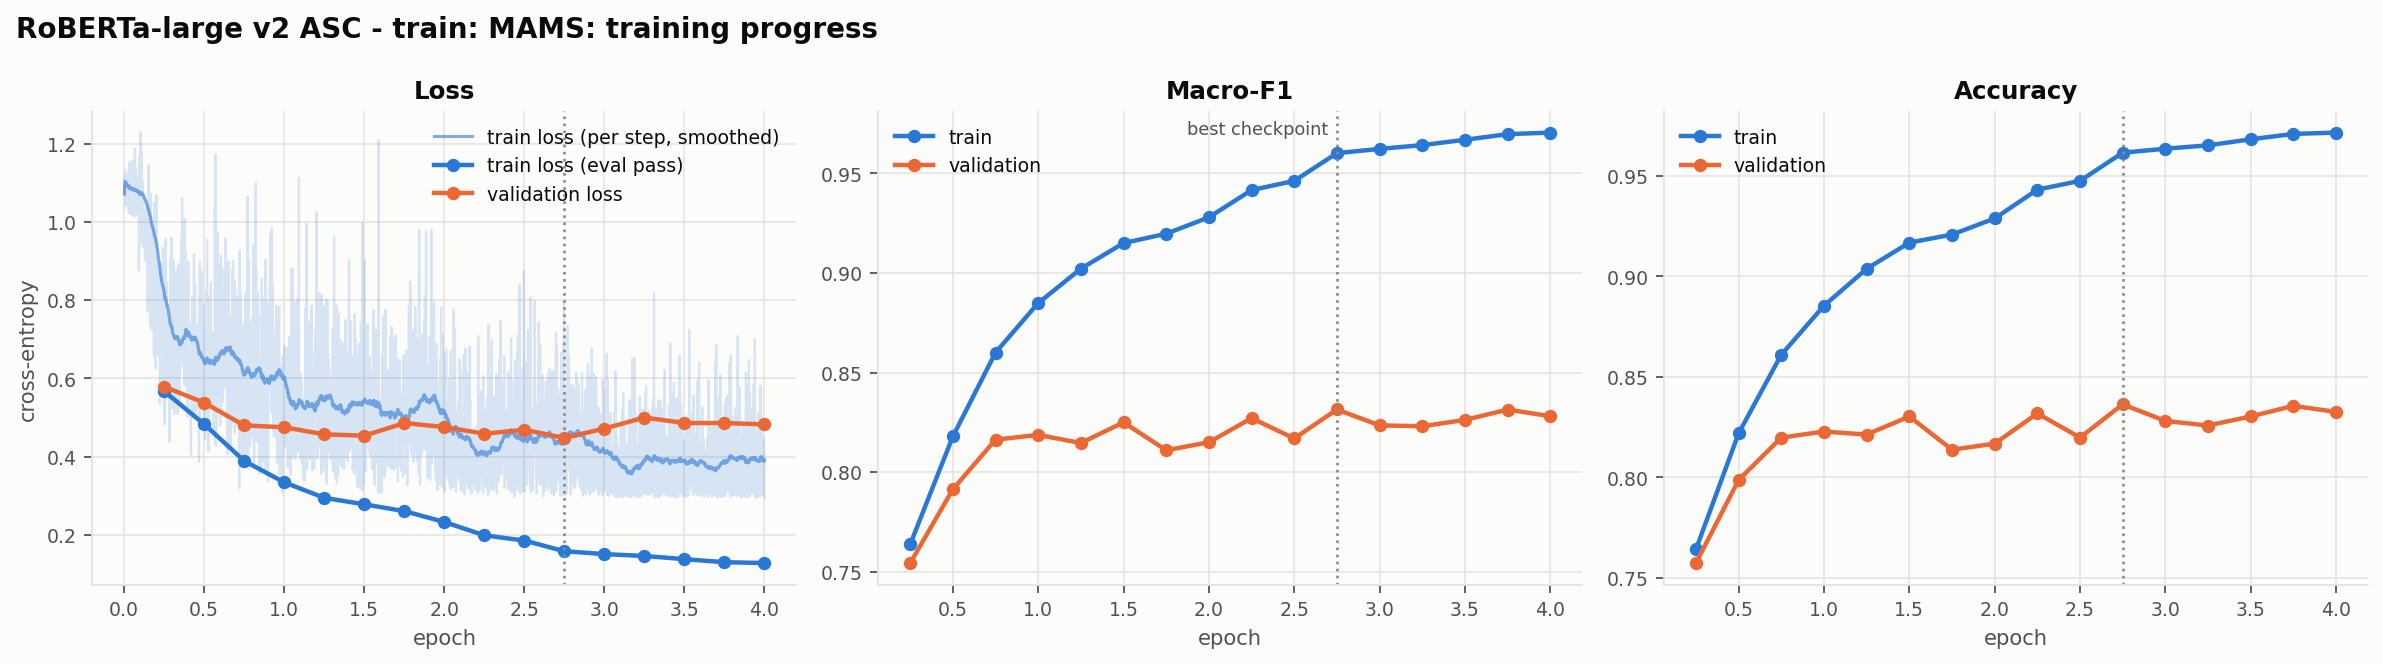

**v2 · ATE · roberta-large-v2_train-mams**

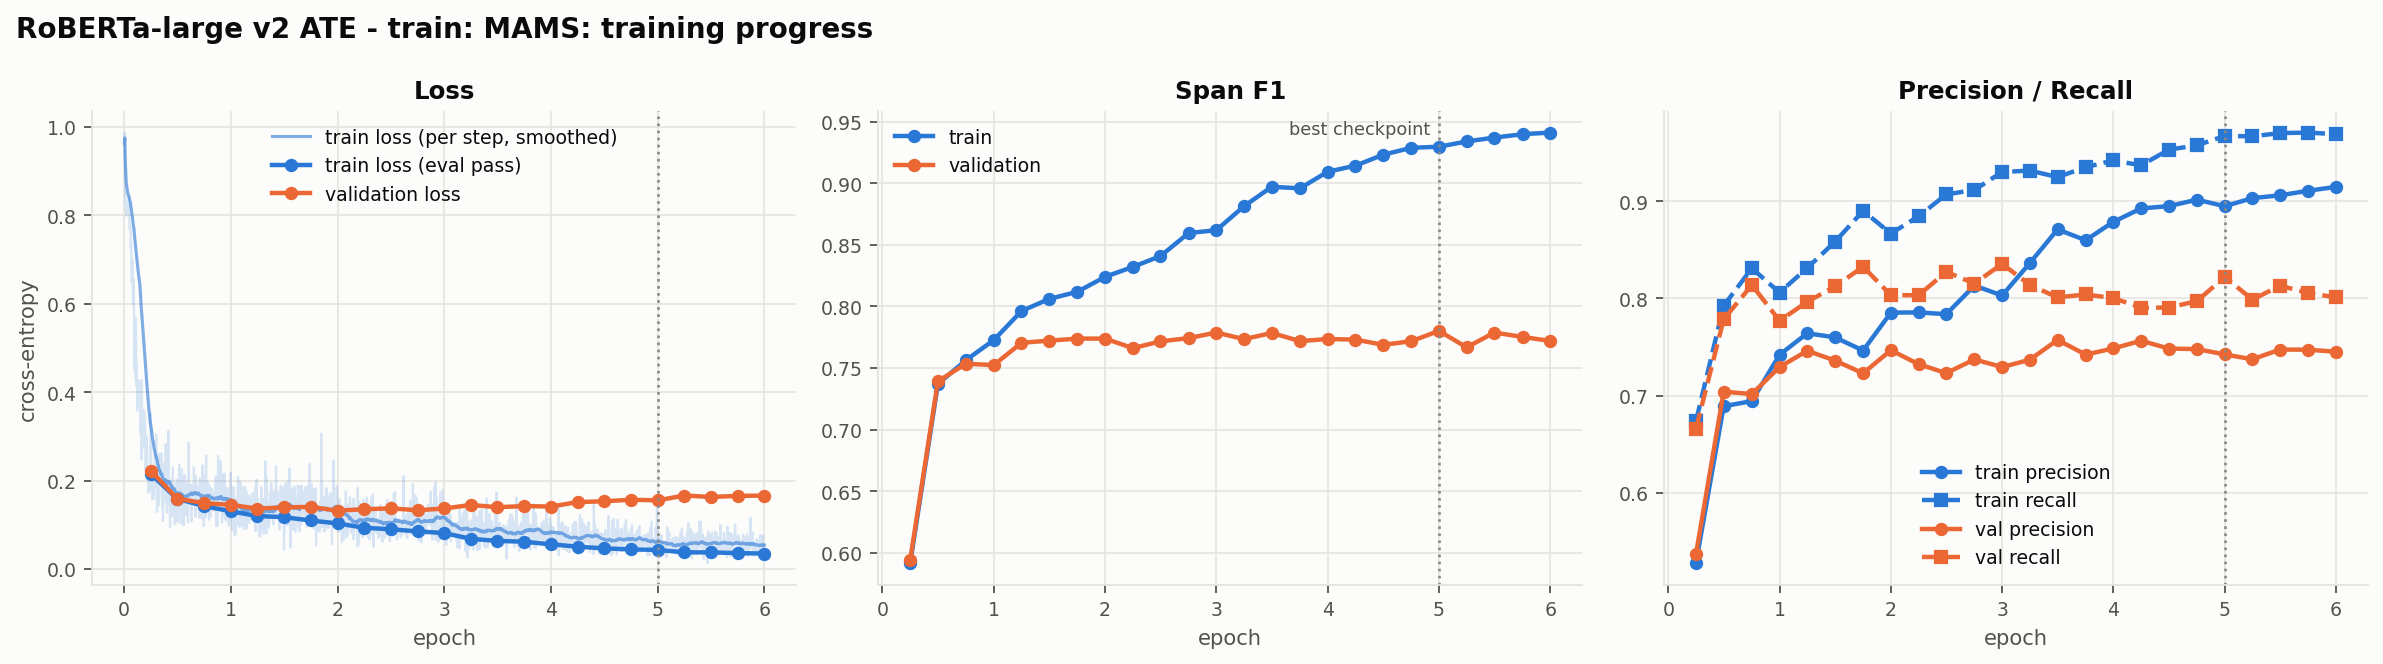

In [13]:
for task, run in [("asc", "roberta-large-v2_train-semeval"), ("asc", "roberta-large-v2_train-mams"),
                  ("ate", "roberta-large-v2_train-mams")]:
    display(Markdown(f"**v2 · {task.upper()} · {run}**"))
    show(V2 / "transformers" / task / run / "training_curves.png")

## 7. v1 → v2 improvements

In [14]:
display(Markdown(open(V2 / "IMPROVEMENTS.md", encoding="utf-8").read()))

# v2 improvements over v1

Reference = v1 RoBERTa-base (the best v1 model). Δ = v2 − v1 (absolute points on the 0–1 scale).

## What changed and why

| v1 observation | v2 change |
|---|---|
| Train macro-F1 → 0.94–0.98 while val plateaus at epoch ~2 and val loss rises (over-fitting) | label smoothing 0.1, FGM adversarial training on embeddings (ε=0.5), layer-wise LR decay so lower layers move less |
| [CLS]-only head cannot tell which aspect it is judging in multi-aspect sentences (MAMS: every sentence) | aspect wrapped with `#` markers in the sentence + head on [CLS] ⊕ mean(aspect sub-word states) |
| Val F1 jumps ±3 pts between checks on SemEval's 221-aspect val split | 4 validation checks per epoch, batch 16 (more updates), patience in epochs |
| ATE decoding could emit invalid `O → I` sequences | BIO-constrained Viterbi decoding |
| Base-size encoder | RoBERTa-large (bf16, gradient checkpointing to fit the 8 GB GPU) |

## ASC macro-F1

| train | test | setting | v1 RoBERTa-base | RoBERTa-base v2 | Δ RoBERTa-base v2 | RoBERTa-large v2 | Δ RoBERTa-large v2 |
|---|---|---|---|---|---|---|---|
| semeval | semeval | in-domain | 0.7748 | 0.7790 | +0.0043 | 0.7988 | +0.0240 |
| semeval | mams | cross-dataset | 0.4824 | 0.5739 | +0.0915 | 0.5416 | +0.0592 |
| mams | semeval | cross-dataset | 0.7208 | 0.6911 | -0.0297 | 0.7321 | +0.0113 |
| mams | mams | in-domain | 0.8403 | 0.8449 | +0.0046 | 0.8506 | +0.0103 |

## ASC accuracy

| train | test | setting | v1 RoBERTa-base | RoBERTa-base v2 | Δ RoBERTa-base v2 | RoBERTa-large v2 | Δ RoBERTa-large v2 |
|---|---|---|---|---|---|---|---|
| semeval | semeval | in-domain | 0.8041 | 0.8197 | +0.0157 | 0.8323 | +0.0282 |
| semeval | mams | cross-dataset | 0.4873 | 0.5831 | +0.0958 | 0.5561 | +0.0689 |
| mams | semeval | cross-dataset | 0.7539 | 0.7273 | -0.0266 | 0.7618 | +0.0078 |
| mams | mams | in-domain | 0.8451 | 0.8503 | +0.0052 | 0.8563 | +0.0112 |

## ASC neutral-class F1 (weakest class in v1)

| train | test | setting | v1 RoBERTa-base | RoBERTa-base v2 | Δ RoBERTa-base v2 | RoBERTa-large v2 | Δ RoBERTa-large v2 |
|---|---|---|---|---|---|---|---|
| semeval | semeval | in-domain | 0.6809 | 0.6272 | -0.0537 | 0.6906 | +0.0097 |
| semeval | mams | cross-dataset | 0.3313 | 0.4080 | +0.0766 | 0.3157 | -0.0157 |
| mams | semeval | cross-dataset | 0.6528 | 0.6104 | -0.0424 | 0.6715 | +0.0187 |
| mams | mams | in-domain | 0.8645 | 0.8724 | +0.0079 | 0.8765 | +0.0120 |

## ATE span F1

| train | test | setting | v1 RoBERTa-base | RoBERTa-base v2 | Δ RoBERTa-base v2 | RoBERTa-large v2 | Δ RoBERTa-large v2 |
|---|---|---|---|---|---|---|---|
| semeval | semeval | in-domain | 0.8591 | 0.8456 | -0.0135 | 0.8607 | +0.0016 |
| semeval | mams | cross-dataset | 0.4396 | 0.3825 | -0.0571 | 0.3808 | -0.0588 |
| mams | semeval | cross-dataset | 0.3948 | 0.4149 | +0.0201 | 0.4032 | +0.0084 |
| mams | mams | in-domain | 0.7620 | 0.7801 | +0.0181 | 0.7683 | +0.0063 |

## End-to-end ATE → ASC pair F1

| train | test | setting | v1 RoBERTa-base | RoBERTa-base v2 | Δ RoBERTa-base v2 | RoBERTa-large v2 | Δ RoBERTa-large v2 |
|---|---|---|---|---|---|---|---|
| semeval | semeval | in-domain | 0.6914 | 0.7017 | +0.0103 | 0.7095 | +0.0181 |
| semeval | mams | cross-dataset | 0.2757 | 0.2883 | +0.0126 | 0.2950 | +0.0193 |
| mams | semeval | cross-dataset | 0.2986 | 0.3079 | +0.0093 | 0.3257 | +0.0271 |
| mams | mams | in-domain | 0.6550 | 0.6713 | +0.0163 | 0.6619 | +0.0069 |

## Generalisation gap at the selected checkpoint (train − val main metric)

| model | task | train | best_epoch | train_metric | val_metric | gap |
|---|---|---|---|---|---|---|
| BERT-base v1 | asc | mams | 5.5000 | 0.9876 | 0.8243 | 0.1634 |
| RoBERTa-base v1 | asc | mams | 5.0000 | 0.9822 | 0.8306 | 0.1516 |
| RoBERTa-base v2 | asc | mams | 1.5000 | 0.9104 | 0.8322 | 0.0782 |
| RoBERTa-large v2 | asc | mams | 2.7500 | 0.9602 | 0.8315 | 0.1287 |
| BERT-base v1 | asc | semeval | 3.5000 | 0.8926 | 0.7095 | 0.1830 |
| RoBERTa-base v1 | asc | semeval | 2.5000 | 0.8374 | 0.7877 | 0.0497 |
| RoBERTa-base v2 | asc | semeval | 4.5040 | 0.9944 | 0.7758 | 0.2186 |
| RoBERTa-large v2 | asc | semeval | 1.7480 | 0.9186 | 0.7910 | 0.1275 |
| BERT-base v1 | ate | mams | 5.0000 | 0.9728 | 0.7761 | 0.1967 |
| RoBERTa-base v1 | ate | mams | 6.5040 | 0.9591 | 0.7840 | 0.1751 |
| RoBERTa-base v2 | ate | mams | 3.0000 | 0.8742 | 0.7893 | 0.0849 |
| RoBERTa-large v2 | ate | mams | 5.0000 | 0.9296 | 0.7802 | 0.1494 |
| BERT-base v1 | ate | semeval | 5.5000 | 0.9977 | 0.8294 | 0.1683 |
| RoBERTa-base v1 | ate | semeval | 8.0000 | 0.9993 | 0.8657 | 0.1336 |
| RoBERTa-base v2 | ate | semeval | 3.7500 | 0.9886 | 0.8756 | 0.1130 |
| RoBERTa-large v2 | ate | semeval | 4.0000 | 0.9948 | 0.8596 | 0.1352 |

Figures: `improvements/v1_vs_v2_*.png`, `improvements/*_val_curves_v1_vs_v2.png`; per-run training curves: `transformers/<task>/<run>/training_curves.png`; full tables: `summary.md`.


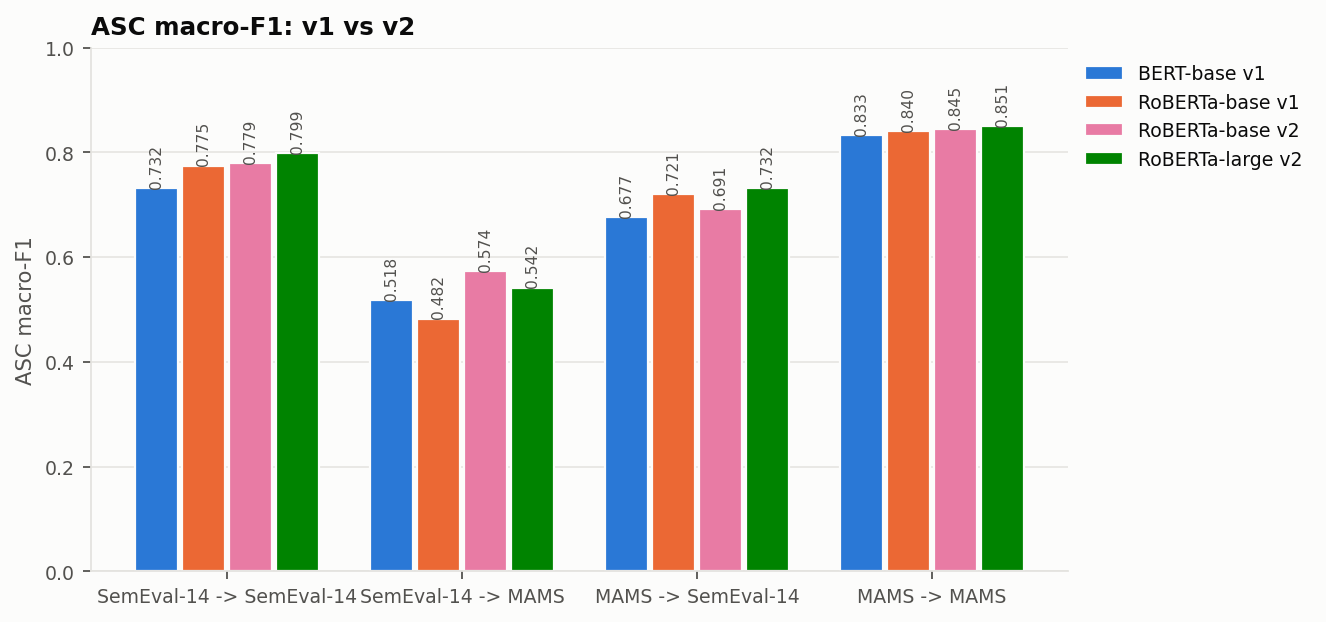

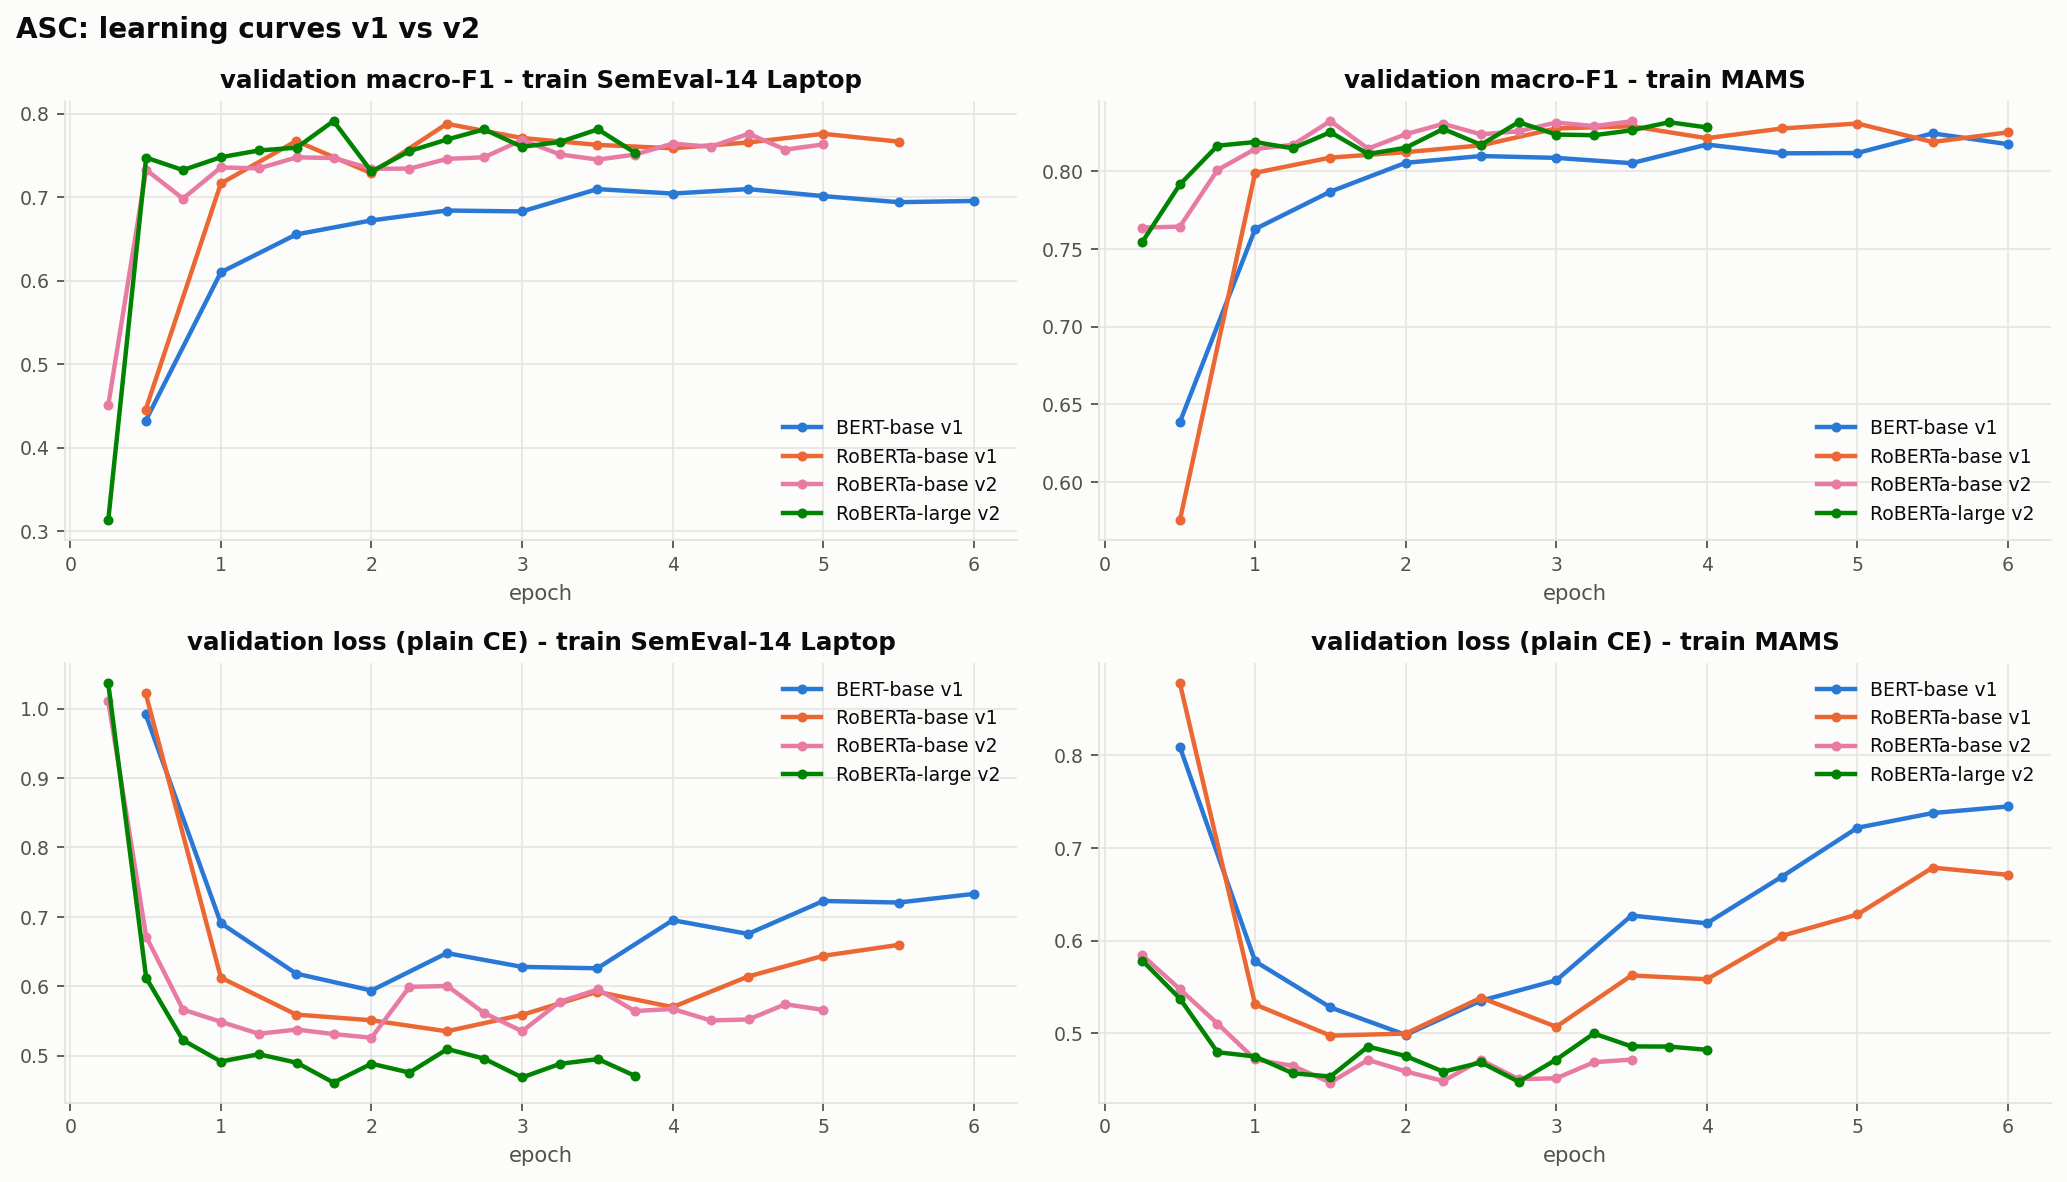

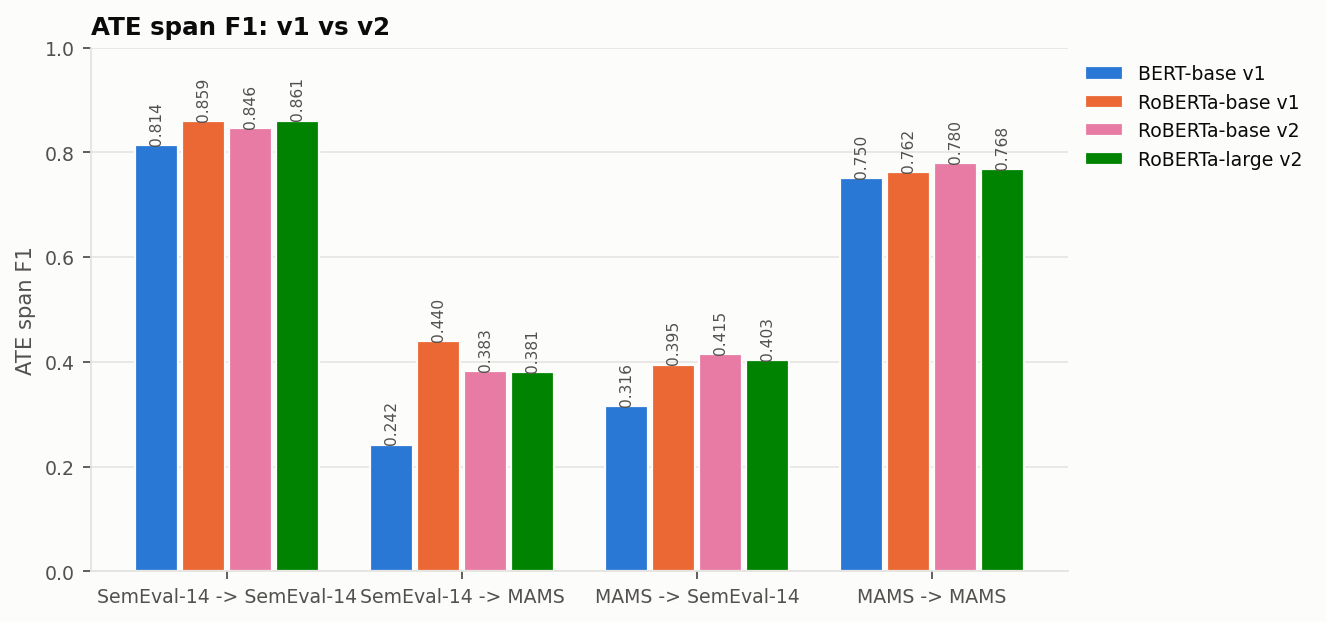

In [15]:
show(V2 / "improvements" / "v1_vs_v2_asc_macro_f1.png")
show(V2 / "improvements" / "asc_val_curves_v1_vs_v2.png")
show(V2 / "improvements" / "v1_vs_v2_ate_f1.png")

## 8. Error analysis

Each test instance is tagged with rule-based linguistic phenomena: negation, contrast, multiple aspects,
multiple polarities in the sentence, implicit sentiment (no word from Liu's opinion lexicon) and long-range
dependency (closest opinion word at least 5 tokens from the aspect). Accuracy is then computed per group.

all  negation  contrast  multi_aspect  \
train   model                                                        
semeval TF-IDF+LR         0.6708    0.5175    0.5190        0.6623   
        TF-IDF+SVM        0.6646    0.5385    0.5316        0.6649   
mams    TF-IDF+LR         0.7148    0.6750    0.6932        0.7148   
        TF-IDF+SVM        0.7253    0.6886    0.7005        0.7253   
        BERT-base v1      0.8368    0.8136    0.8382        0.8368   
semeval BERT-base v1      0.7759    0.6713    0.6835        0.7652   
mams    RoBERTa-base v1   0.8451    0.8227    0.8406        0.8451   
semeval RoBERTa-base v1   0.8041    0.6993    0.6329        0.7968   
        RoBERTa-base v2   0.8197    0.7413    0.7342        0.8179   
        RoBERTa-large v2  0.8323    0.7133    0.7848        0.8391   
mams    RoBERTa-base v2   0.8503    0.8455    0.8792        0.8503   
        RoBERTa-large v2  0.8563    0.8295    0.8357        0.8563   

                          multi_polarity  implicit  long_range  
train   model                                                   
semeval TF-IDF+LR                 0.4854    0.5634      0.6268  
        TF-IDF+SVM                0.4563    0.5352      0.6056  
mams    TF-IDF+LR                 0.7148    0.7839      0.7149  
        TF-IDF+SVM                0.7253    0.7802      0.7210  
        BERT-base v1              0.8368    0.8718      0.8289  
semeval BERT-base v1              0.5243    0.6831      0.6972  
mams    RoBERTa-base v1           0.8451    0.8571      0.8473  
semeval RoBERTa-base v1           0.5728    0.7465      0.7606  
        RoBERTa-base v2           0.7184    0.7535      0.7183  
        RoBERTa-large v2          0.7379    0.7817      0.7887  
mams    RoBERTa-base v2           0.8503    0.8755      0.8391  
        RoBERTa-large v2          0.8563    0.8718      0.8493

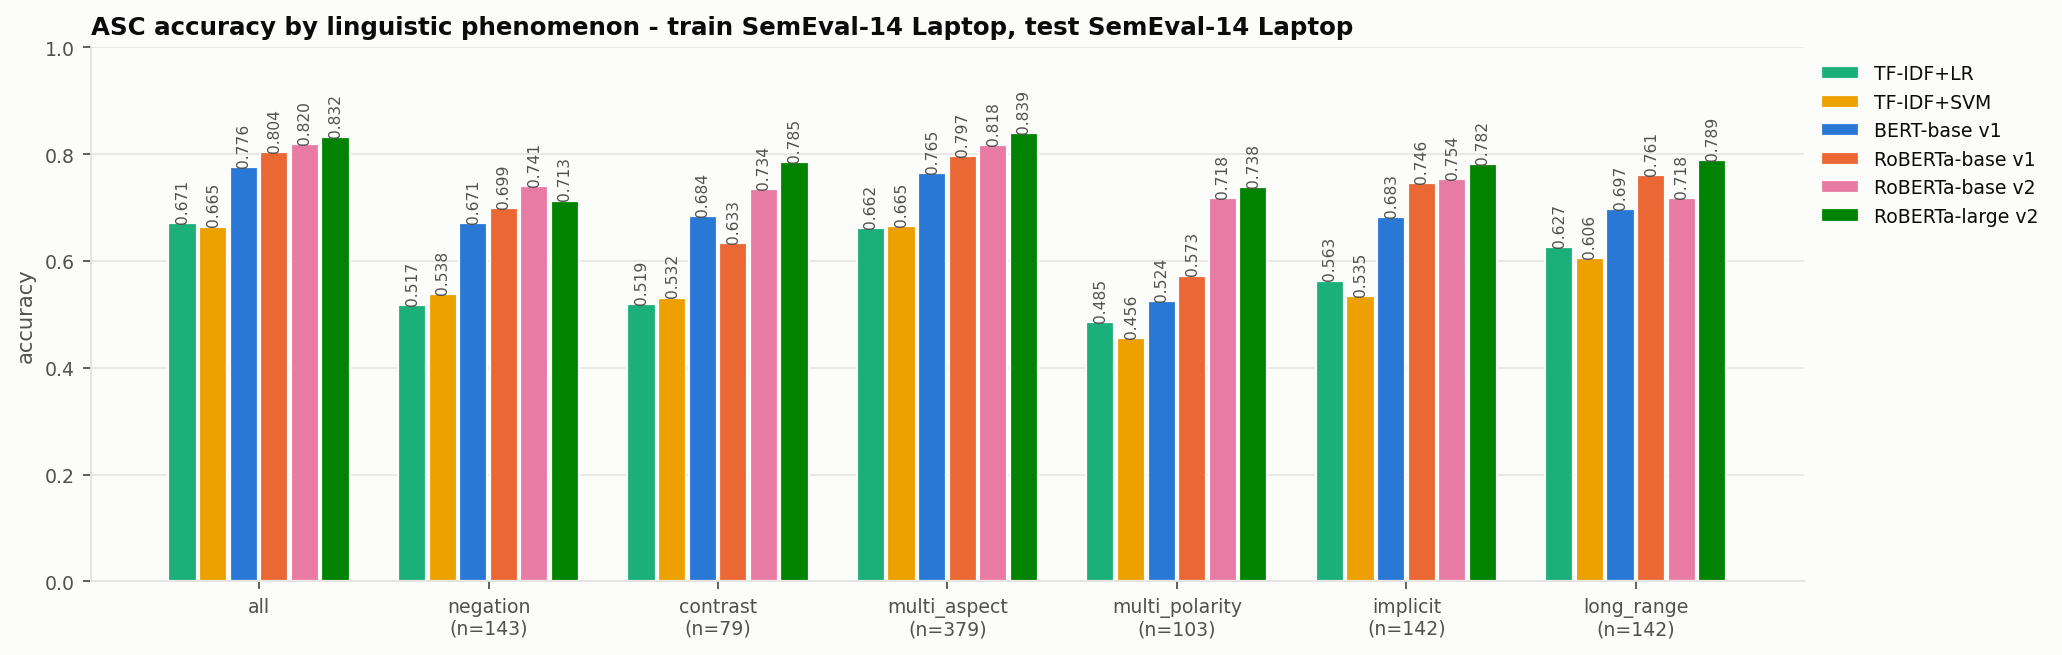

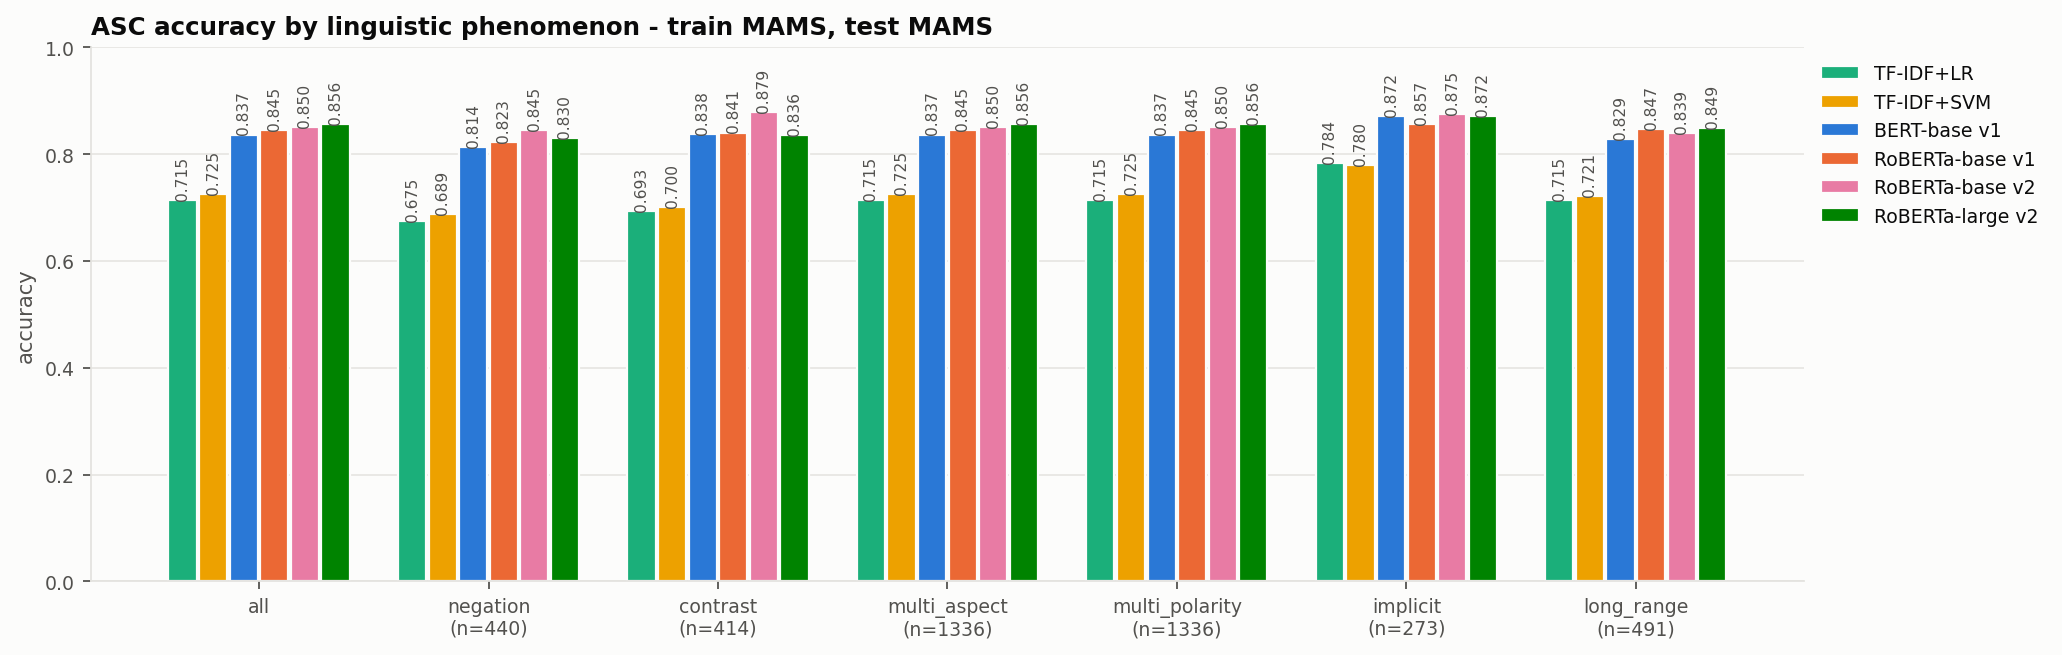

In [16]:
ea = pd.read_csv(V2 / "error_analysis" / "accuracy_by_phenomenon.csv")
cols = ["all", "negation", "contrast", "multi_aspect", "multi_polarity", "implicit", "long_range"]
display(ea[ea.train == ea.test].set_index(["train", "model"])[cols])
show(V2 / "error_analysis" / "phenomena_semeval_to_semeval.png")
show(V2 / "error_analysis" / "phenomena_mams_to_mams.png")

In [17]:
# a sample of the remaining mistakes of the best model on SemEval
err = pd.read_csv(V2 / "error_analysis" / "errors_RoBERTa-large v2_semeval_to_semeval.csv")
print(len(err), "misclassified aspects")
err.sample(10, random_state=0)

107 misclassified aspects


,sid,text,aspect,polarity,pred,phenomena
84,994:1,"I bought it to be able to dedicate a small, portable laptop to my writing and was surprised to learn that I needed t...",word processing program,neutral,negative,long_range
10,104:1,I've already upgraded o Mavericks and I am impressed with everything about this computer.,Mavericks,positive,neutral,NaN
75,325:1,"Additionally, there is barely a ventilation system in the computer, and even the simple activity of watching videos ...",playing steam games,neutral,negative,"negation,multi_aspect,multi_polarity,long_range"
2,792:2,The baterry is very longer.,baterry,positive,negative,implicit
24,786:1477,It's ok but doesn't have a disk drive which I didn't know until after I bought it.,disk drive,neutral,negative,"negation,contrast,implicit"
99,834:1,A veryimportant feature is Firewire 800 which in my experience works better then USB3 (in PC enabled with USB3)I was...,Windows 7,positive,neutral,"negation,multi_aspect,multi_polarity,long_range"
106,280:11,Screen - although some people might complain about low res which I think is ridiculous.,res,positive,negative,"contrast,multi_aspect"
7,286:15,"I opted for the SquareTrade 3-Year Computer Accidental Protection Warranty ($1500-2000) which also support ""accident...",SquareTrade 3-Year Computer Accidental Protection Warranty,positive,neutral,"negation,multi_aspect,multi_polarity"
16,923:1,"I use it mostly for content creation (Audio, video, photo editing) and its reliable.",content creation,positive,neutral,"multi_aspect,long_range"
86,11:1,"The case is now slightly larger than the previous generation, but the lack of an external power supply justifies the...",external power supply,neutral,negative,"contrast,multi_aspect,multi_polarity"


## 9. Live demo: raw sentence → aspects → sentiment

Two models (RoBERTa-base, v2 recipe, trained on SemEval Laptops) are chained: the ATE tagger finds aspect terms,
then the ASC classifier assigns a polarity to each one. The first run trains them (about 5 minutes on the GPU)
and caches them under `models/demo/`; later runs load the cache.

In [18]:
from absa.pipeline import train_or_load
absa_pipe = train_or_load(data, train_on="semeval")

W1031 20:29:18.729000 125392 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


[demo] training ATE model on semeval (one-off, a few minutes)...
  encoded train=2741 val=304 in 0.1s (max len 91) | device=NVIDIA GeForce RTX 4060 Laptop GPU amp=torch.bfloat16


demo ATE | epoch 1/8:   0%|          | 0/172 [00:00<?, ?it/s]

  [ep  0.25] loss tr=0.5357/0.2127 val=0.2230 | f1 tr=0.0000 val=0.0000  *best*


  [ep  0.50] loss tr=0.1671/0.0985 val=0.1002 | f1 tr=0.6202 val=0.6494  *best*


  [ep  0.75] loss tr=0.0922/0.0655 val=0.0738 | f1 tr=0.7769 val=0.7630  *best*


... (55 outputs left out)

  [ep  4.50] loss tr=0.3172/0.0694 val=0.5520 | macro_f1 tr=0.9944 val=0.7758  *best*


  [ep  4.75] loss tr=0.3347/0.0708 val=0.5740 | macro_f1 tr=0.9930 val=0.7568


  [ep  5.00] loss tr=0.3171/0.0671 val=0.5657 | macro_f1 tr=0.9948 val=0.7630


  done in 1.5 min - best val macro_f1=0.7758 @ epoch 4.504


In [19]:
examples = [
    "The laptop has an excellent display, but the battery life is disappointing.",
    "The battery life is excellent but the keyboard is uncomfortable.",
    "Customer support never answered my emails, although the screen is gorgeous.",
    "It boots up fast and the trackpad works fine, but the speakers are tinny.",
    "I use it mostly for browsing and the price was okay.",
]
demo_df = absa_pipe(examples)
demo_df.to_csv(V2 / "demo_predictions.csv", index=False)
demo_df

,sentence,aspect,polarity,confidence
0,"The laptop has an excellent display, but the battery life is disappointing.",display,positive,0.947
1,"The laptop has an excellent display, but the battery life is disappointing.",battery life,negative,0.933
2,The battery life is excellent but the keyboard is uncomfortable.,battery life,positive,0.944
3,The battery life is excellent but the keyboard is uncomfortable.,keyboard,negative,0.939
4,"Customer support never answered my emails, although the screen is gorgeous.",Customer support,negative,0.936
5,"Customer support never answered my emails, although the screen is gorgeous.",screen,positive,0.937
6,"It boots up fast and the trackpad works fine, but the speakers are tinny.",boots up,positive,0.947
7,"It boots up fast and the trackpad works fine, but the speakers are tinny.",trackpad,positive,0.942
8,"It boots up fast and the trackpad works fine, but the speakers are tinny.",speakers,negative,0.949
9,I use it mostly for browsing and the price was okay.,price,positive,0.947


In [20]:
# try your own review
absa_pipe("The keyboard feels cheap but the processor handles video editing without any lag.")

,sentence,aspect,polarity,confidence
0,The keyboard feels cheap but the processor handles video editing without any lag.,keyboard,negative,0.728
1,The keyboard feels cheap but the processor handles video editing without any lag.,processor,positive,0.942
2,The keyboard feels cheap but the processor handles video editing without any lag.,video editing,positive,0.945
